In [2]:
import sys
sys.path.append('../')

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import seaborn as sns
import model
import json, csv
import mvpy
import plots

from copy import deepcopy

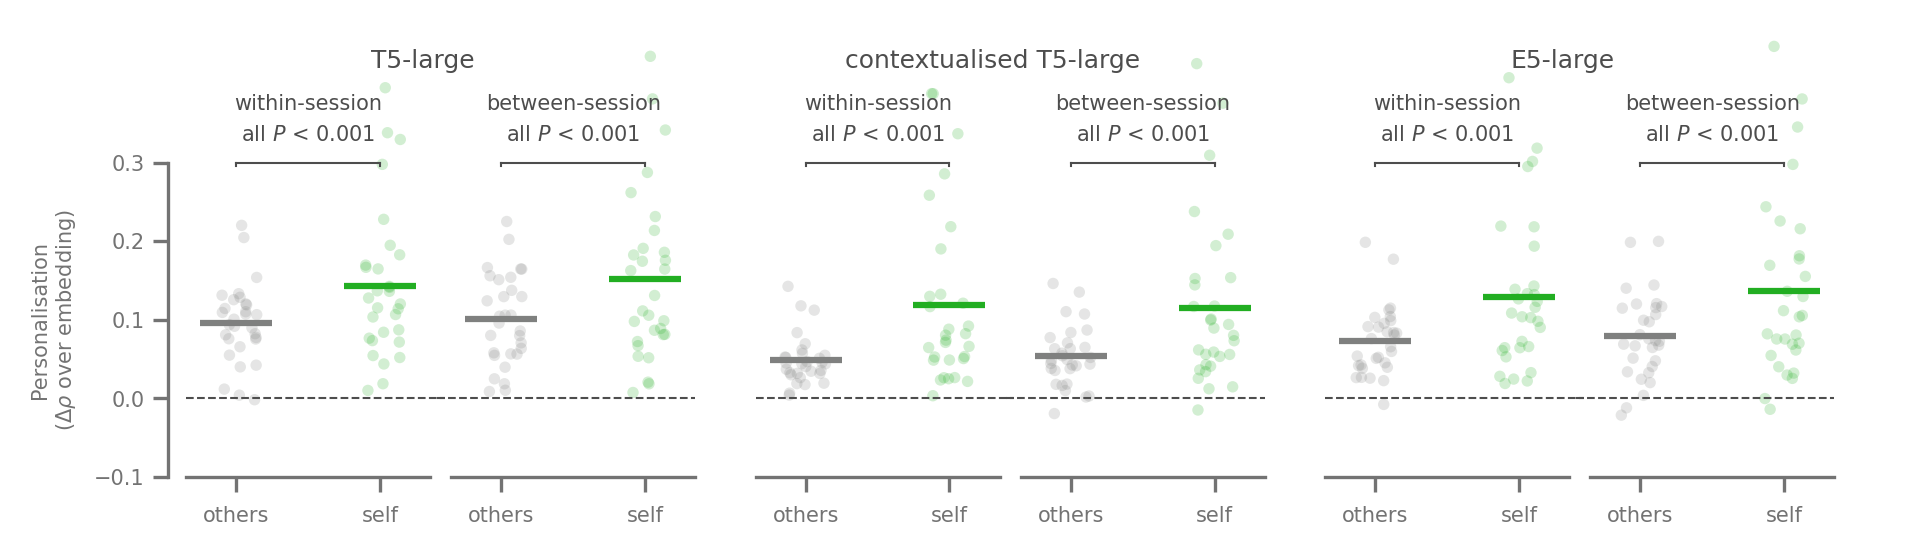

In [3]:
hypothesis_test = 'sign'
hypothesis_alternative = 'two-sided'
hypothesis_method = 'holm'
hypothesis_se = 'within'

run = 0
exp = 1

mods = [
    't5-large',
    't5-large-context',
    'e5-large'
]

mods_label = [
    fr'T5-large',
    fr'contextualised T5-large',
    fr'E5-large',
]

# initialise plot
fig, ax = plt.subplots(figsize = (6.4, 2.0), dpi = 300)

cvs = []
offset_ax = 0.075

for mod_i, mod in enumerate(mods):
    share = 1 / len(mods)
    cv5 =  ax.inset_axes([share * mod_i - offset_ax, 0.0, share + offset_ax, 1.0])
    cv5.axis('off')

    cols = np.array([
        plots.colours.HL_EMBEDDING,
        plots.colours.HL_OTHERS,
        plots.colours.HL_SELF
    ])

    # within-session boards (5 folds)
    cv5_a1 = cv5.inset_axes([0.21, 0.075, 0.35, 0.65])

    R = torch.load(f'../data/ds-exp{exp}/derivatives/run-00{run}/tasks/task-matrain_bse0-{mod}_mod-delta.pt', map_location=torch.device('cpu'))
    R_base = R['rho_BE'].squeeze().cpu().numpy().diagonal()
    R_indiv = R['rho_BZ'].cpu().numpy().diagonal().squeeze()
    R_group = R['rho_BZ'].cpu().numpy()
    R_group = R_group[np.eye(R_group.shape[0], dtype = bool) == False].reshape((R_group.shape[0], R_group.shape[0] - 1)).mean(-1)
    R_noise = R['rho_nc'].cpu().numpy().squeeze()

    R_a = np.array([R_base, R_group, R_indiv])
    R_d = R_a[1:] - R_a[0]
    X_jitter = np.random.uniform(-0.15, 0.15, size = (R_base.shape[0],))

    offset = 0

    for i, R_i in enumerate(R_d):
        mu = R_i.mean()
        se = model.stats.bootstrap_se(R_i)
        x_i = i + X_jitter

        if offset < (mu + 1.96 * se):
            offset = mu + 1.96 * se

        cv5_a1.scatter(x_i, R_i, marker = '.', edgecolor = 'None', facecolor = cols[i+1], s = 30, alpha = 0.2, clip_on = False)
        cv5_a1.scatter([i], [mu], color = cols[i+1], marker = '_', s = 300, clip_on = False, zorder = 2)

    design = [(1, 0), (2, 1), (2, 0)]
    group = model.stats.sample_tests(R_a, test = hypothesis_test, alternative = hypothesis_alternative, method = hypothesis_method, se = hypothesis_se)
    pairwise = model.stats.pairwise_tests(R_a, design, test = hypothesis_test, alternative = hypothesis_alternative, method = hypothesis_method, se = hypothesis_se)

    model.stats.save_results(group, f'./deliverable/csv/suppfig2/{mod}_wthn_group.csv')
    model.stats.save_results(pairwise, f'./deliverable/csv/suppfig2/{mod}_wthn_pairs.csv')

    # significance
    count = 0.0
    gain = 0.015
    min_p = 0.0

    for i, (ii, jj) in enumerate(design):
        p_i = pairwise[i]['p_cor']
        if p_i < .05:
            if p_i > min_p:
                min_p = p_i

            if i != 1: continue

            sig = 'n.s.' if p_i > 0.05 else '*' if p_i > 1e-2 else '**' if p_i > 1e-3 else '***'
            yy = 0.30 + count * gain #0.2 + offset + count * gain
            cv5_a1.plot([ii - 1, jj - 1], [yy, yy], color = plots.colours.H2, linewidth = 0.5, clip_on = False)
            cv5_a1.plot([ii - 1, ii - 1], [yy, yy - gain / 4], color = plots.colours.H2, linewidth = 0.5, clip_on = False)
            cv5_a1.plot([jj - 1, jj - 1], [yy, yy - gain / 4], color = plots.colours.H2, linewidth = 0.5, clip_on = False)
            count += 1

    rep_p = 'n.s.' if min_p > .05 else fr'$P$ < 0.05' if min_p > 1e-2 else '$P$ < 0.01' if min_p > 1e-3 else '$P$ < 0.001'
    cv5_a1.annotate(f'all {rep_p}', xy = (0, 0), xytext = (0.5, 0.335), ha = 'center', va = 'center', fontsize = 5, color = plots.colours.H2)

    # between-session boards (5 folds)
    cv5_a2 = cv5.inset_axes([0.59, 0.075, 0.35, 0.65])

    R = torch.load(f'../data/ds-exp{exp}/derivatives/run-00{run}/tasks/task-macross_bse0-{mod}_mod-delta.pt', map_location=torch.device('cpu'))
    R_base = R['rho_BE'].squeeze().cpu().numpy().diagonal()
    R_indiv = R['rho_BZ'].cpu().numpy().diagonal().squeeze()
    R_group = R['rho_BZ'].cpu().numpy()
    R_group = R_group[np.eye(R_group.shape[0], dtype = bool) == False].reshape((R_group.shape[0], R_group.shape[0] - 1)).mean(-1)

    R_a = np.array([R_base, R_group, R_indiv])
    R_d = R_a[1:] - R_a[0]

    offset = 0

    for i, R_i in enumerate(R_d):
        mu = R_i.mean()
        se = model.stats.bootstrap_se(R_i)
        x_i = i + X_jitter

        if offset < (mu + 1.96 * se):
            offset = mu + 1.96 * se

        cv5_a2.scatter(x_i, R_i, marker = '.', edgecolor = 'None', facecolor = cols[i+1], s = 30, alpha = 0.2, clip_on = False)
        cv5_a2.scatter([i], [mu], color = cols[i+1], marker = '_', s = 300, clip_on = False, zorder = 2)

    design = [(1, 0), (2, 1), (2, 0)]
    group = model.stats.sample_tests(R_a, test = hypothesis_test, alternative = hypothesis_alternative, method = hypothesis_method, se = hypothesis_se)
    pairwise = model.stats.pairwise_tests(R_a, design, test = hypothesis_test, alternative = hypothesis_alternative, method = hypothesis_method, se = hypothesis_se)

    model.stats.save_results(group, f'./deliverable/csv/suppfig2/{mod}_btwn_group.csv')
    model.stats.save_results(pairwise, f'./deliverable/csv/suppfig2/{mod}_btwn_pairs.csv')

    # significance
    count = 0.0#-1.0
    min_p = 0.0

    for i, (ii, jj) in enumerate(design):
        p_i = pairwise[i]['p_cor']
        if p_i < .05:
            if p_i > min_p:
                min_p = p_i

            if i != 1: continue

            sig = 'n.s.' if p_i > 0.05 else '*' if p_i > 1e-2 else '**' if p_i > 1e-3 else '***'
            yy = 0.30 + count * gain #0.2 + offset + count * gain
            cv5_a2.plot([ii - 1, jj - 1], [yy, yy], color = plots.colours.H2, linewidth = 0.5, clip_on = False)
            cv5_a2.plot([ii - 1, ii - 1], [yy, yy - gain / 4], color = plots.colours.H2, linewidth = 0.5, clip_on = False)
            cv5_a2.plot([jj - 1, jj - 1], [yy, yy - gain / 4], color = plots.colours.H2, linewidth = 0.5, clip_on = False)
            count += 1

    rep_p = 'n.s.' if min_p > .05 else fr'$P$ < 0.05' if min_p > 1e-2 else '$P$ < 0.01' if min_p > 1e-3 else '$P$ < 0.001'
    cv5_a2.annotate(f'all {rep_p}', xy = (0, 0), xytext = (0.5, 0.335), ha = 'center', va = 'center', fontsize = 5, color = plots.colours.H2)

    for i, ax_i in enumerate([cv5_a1, cv5_a2]):
        xext = 0.1
        xmin, xmax = (0.0, xext) if i == 0 else (-xext, 0.0)
        ax_i.plot([-0.35+xmin, 1.35+xmax], [0, 0], linewidth = 0.5, color = plots.colours.H2, linestyle = '--', clip_on = False)

        label = 'within-session' if i == 0 else 'between-session'
        ax_i.annotate(label, xy = (0, 0), xytext = (0.5, 0.375), ha = 'center', va = 'center', fontsize = 5, color = plots.colours.H2, annotation_clip = False)

        xticks = ['others', 'self']# if i == 0 else []
        ylabel = 'Personalisation\n' + fr'($\Delta\rho$ over embedding)' if i == 0 else ''
        yticks = [-0.1, 0.0, 0.1, 0.2, 0.3] if i == 0 else []
        yvis = True if i == 0 else False
        ypos = -0.075

        ax_i.set_xlim([-0.35, 1.35])
        ax_i.set_xticks([0, 1])
        ax_i.set_xticklabels(xticks, fontsize = 5)
        ax_i.set_ylim([-0.1, 0.3])
        ax_i.set_yticks(yticks)
        ax_i.set_ylabel(ylabel, fontsize = 5)
        ax_i.tick_params(axis = 'y', labelsize = 5, pad = 2)

        ax_i.yaxis.label.set_color(plots.colours.H3)
        ax_i.tick_params(axis = 'x', colors = plots.colours.H3)
        ax_i.tick_params(axis = 'y', colors = plots.colours.H3)
        ax_i.spines['bottom'].set_color(plots.colours.H3)
        ax_i.spines['left'].set_color(plots.colours.H3)

        sns.despine(ax = ax_i)
        ax_i.spines['left'].set_visible(yvis)
        ax_i.spines['left'].set_position(('axes', ypos))
        
        if mod_i > 0:
            ax_i.set_yticklabels([])
            ax_i.set_ylabel('')
            ax_i.spines['left'].set_visible(False)
            ax_i.tick_params(axis = 'y', which = 'both', length = 0)
    
    cv5.annotate(
        fr'{mods_label[mod_i]}',
        xy = (0.0, 0.0),
        xytext = (0.55, 0.935),
        ha = 'center',
        va = 'center',
        fontsize = 6,
        color = plots.colours.H2,
    )
    
    cvs.append(cv5)
    cvs.append(cv5_a1)
    cvs.append(cv5_a2)

'''
cosmetics
'''

fig.tight_layout()

ax.axis('off')

fig.savefig('./deliverable/png/suppfig2.png', dpi = 900)
fig.savefig('./deliverable/pdf/suppfig2.pdf', dpi = 900, format = 'pdf')
fig.savefig('./deliverable/svg/suppfig2.svg', dpi = 900, format = 'svg')